[![preview notebook](https://img.shields.io/static/v1?label=render%20on&logo=github&color=87ce3e&message=GitHub)](https://github.com/open-atmos/PySDM/blob/main/examples/PySDM_examples/sandbox/Mazur_2027_MSc/animations.ipynb)
[![launch on mybinder.org](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/open-atmos/PySDM.git/main?urlpath=lab/tree/examples/PySDM_examples/sandbox/Mazur_2027_MSc/animations.ipynb)
[![launch on Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/open-atmos/PySDM/blob/main/examples/PySDM_examples/sandbox/Mazur_2027_MSc/animations.ipynb)

This notebook illustrates how particle attributes are sampled in the singular and time-dependent immersion freezing models and compares the resulting distributions.


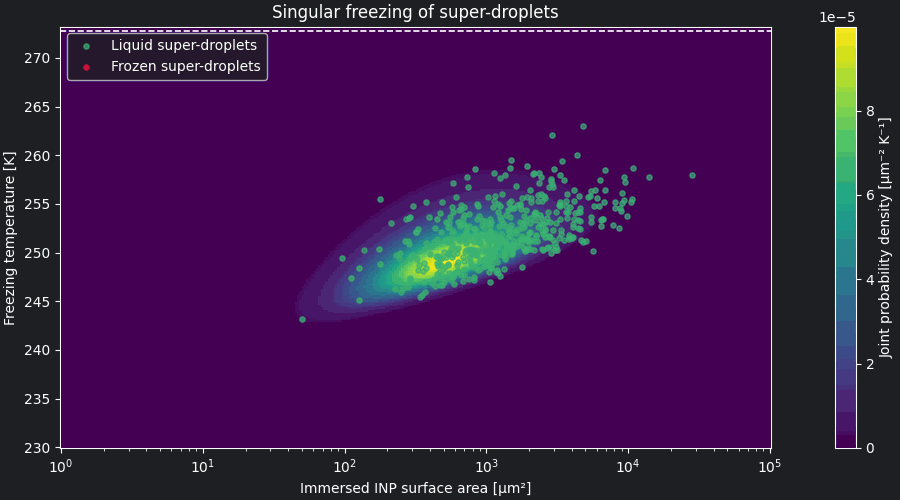

HTML(value="<a href='./tmpjwjyev8d.gif' target='_blank'>./tmpjwjyev8d.gif</a><br>")

In [1]:
import numpy as np
from help_funcs import make_freezing_frame, make_particulator_case
from open_atmos_jupyter_utils import show_anim
from PySDM.physics import si
from PySDM import Formulae
from PySDM_examples.featured.Arabas_et_al_2025.commons import FREEZING_CONSTANTS
from PySDM.initialisation.spectra import Lognormal

formulae=Formulae(
    constants={
            **FREEZING_CONSTANTS["dust"],
        },
    freezing_temperature_spectrum="Niemand_et_al_2012",
    particle_shape_and_density="MixedPhaseSpheres",
)
temperature = np.linspace(230, 273.15, 300) * si.K
area = np.geomspace(1, 1e5, 300) * si.um**2
cooling_rate = 25 *si.K/si.min
T0=273.15*si.K

A, T = np.meshgrid(area, temperature)
pdf = formulae.freezing_temperature_spectrum.pdf(
    T=T,
    A_insol=A,
)
surface_median = formulae.trivia.sphere_surface(
    diameter=2 * 10.0*si.um
)
surface_spectrum = Lognormal(
    norm_factor=1,
    m_mode=surface_median,
    s_geom=2.55,
)
joint_pdf = pdf * surface_spectrum.pdf(A)
particulator = make_particulator_case(singular=True, seed=444, T0=T0)
plot_func = make_freezing_frame(
    particulator,
    area,
    temperature,
    joint_pdf,
    T0,
    cooling_rate,
    singular=True,
)

show_anim(plot_func, range(1,101), duration=0.125, loop=0)


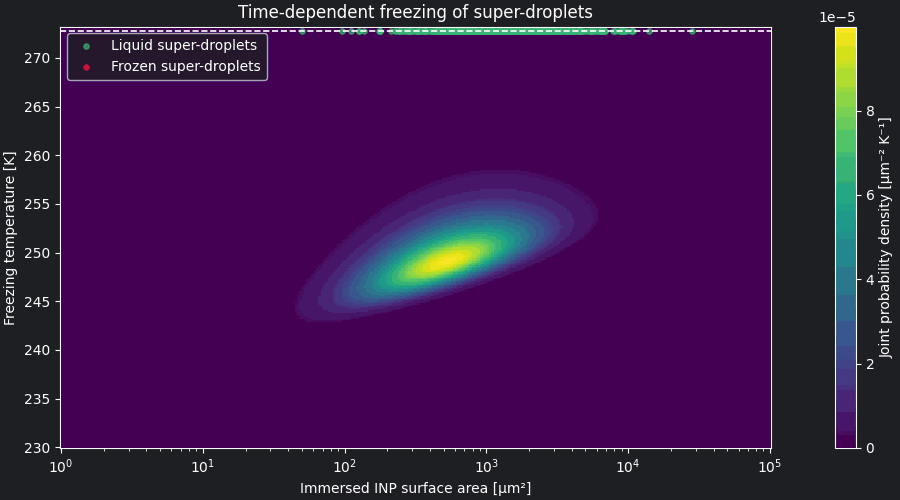

HTML(value="<a href='./tmp40z8fyhe.gif' target='_blank'>./tmp40z8fyhe.gif</a><br>")

In [2]:
particulator = make_particulator_case(singular=False, seed=444, T0=T0)

plot_func = make_freezing_frame(
    particulator,
    area,
    temperature,
    joint_pdf,
    T0,
    cooling_rate,
    singular=False,
)

show_anim(plot_func, range(1,101), duration=0.125, loop=0)



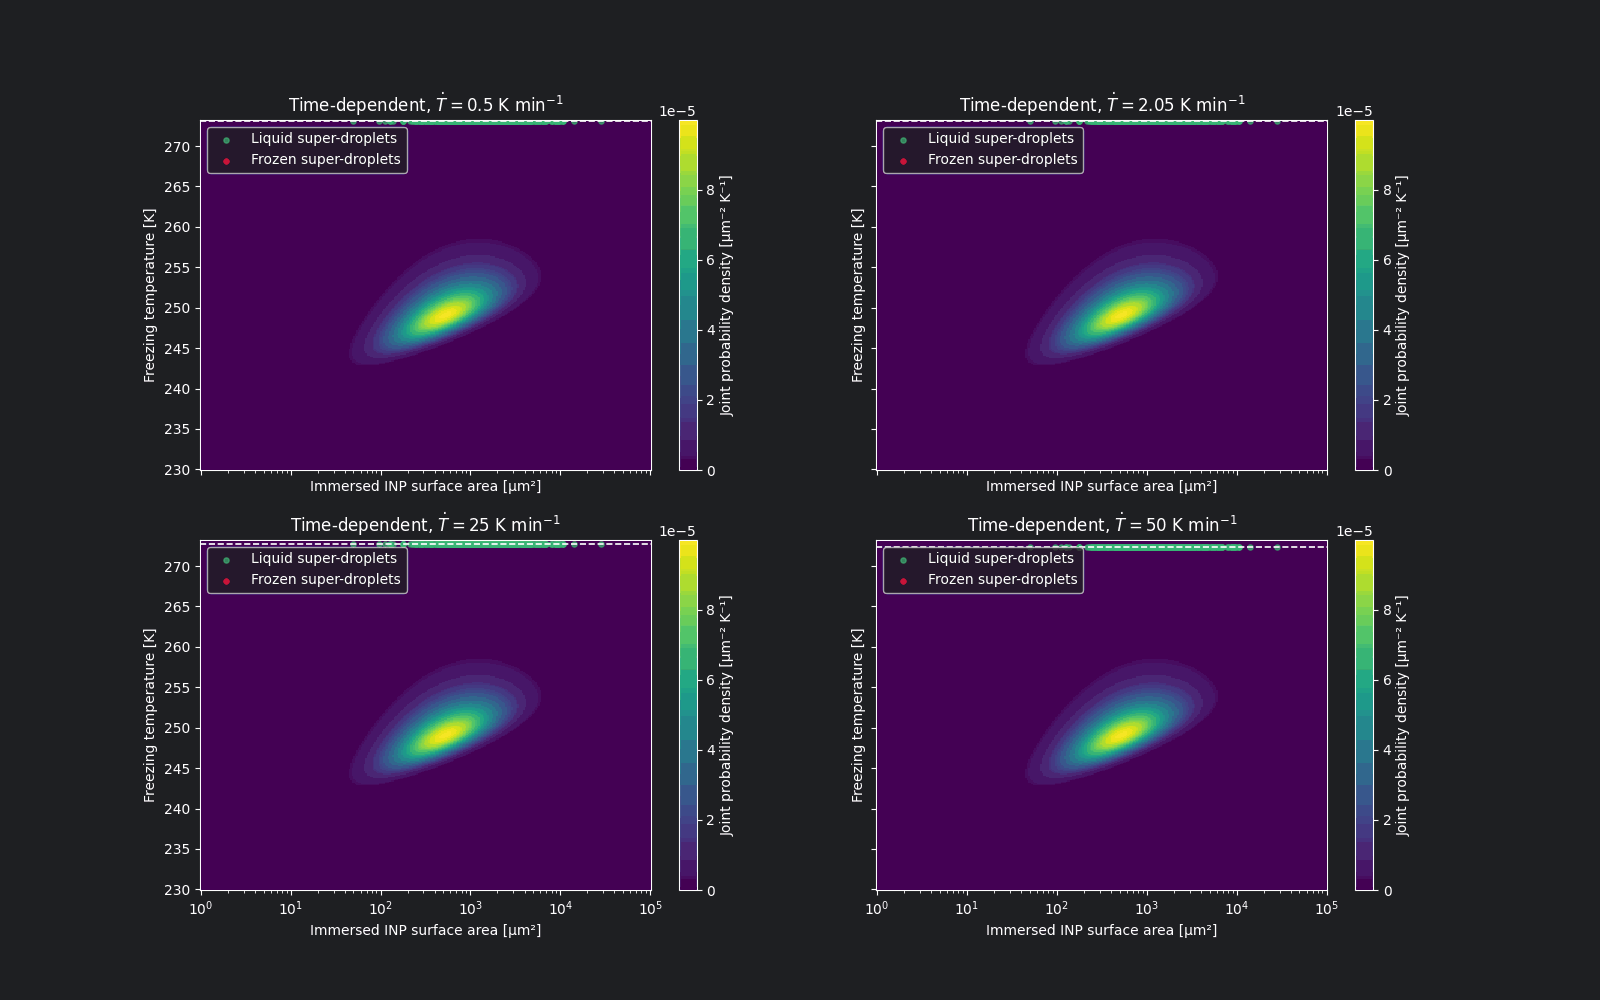

HTML(value="<a href='./tmph3h3djfs.gif' target='_blank'>./tmph3h3djfs.gif</a><br>")

In [3]:
cooling_rates = np.asarray((0.5, 2.05, 25, 50,))*si.K/si.min
n_frames = 50
T_end = 235 *si.K
draw_subplot_help = None
cases = []


for cooling_rate in cooling_rates:
    particulator = make_particulator_case(
        singular=False,
        seed=444,
        T0=T0,
    )

    n_steps = int(np.ceil(
        (T0 - T_end) / (cooling_rate * particulator.dt)
    ))

    frame_steps = np.unique(np.linspace(1, n_steps, n_frames, dtype=int))

    draw_case = make_freezing_frame(
        particulator=particulator,
        area=area,
        temperature=temperature,
        joint_pdf=joint_pdf,
        T0=T0,
        cooling_rate=cooling_rate,
        singular=False,
    )

    cases.append(
        {
            "cooling_rate": cooling_rate,
            "frame_steps": frame_steps,
            "draw": draw_case,
        }
    )

def plot_all_rates(i):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(16, 10),
        sharex=True,
        sharey=True,
    )

    for ax, case in zip(axes.flat, cases):
        last_index = len(case["frame_steps"]) - 1
        step_index = min(i, last_index)
        case["draw"](case["frame_steps"][step_index],ax)

        ax.set_title(
            rf"Time-dependent, "
            rf"$\dot{{T}}={case['cooling_rate'] / (si.K / si.min):g}$ K min$^{{-1}}$"
        )

    return fig

show_anim(
    plot_all_rates,
    range(n_frames),
    duration=0.125,
    loop=0,
)

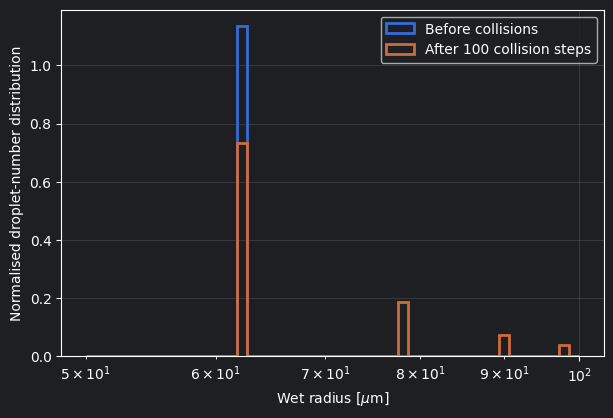


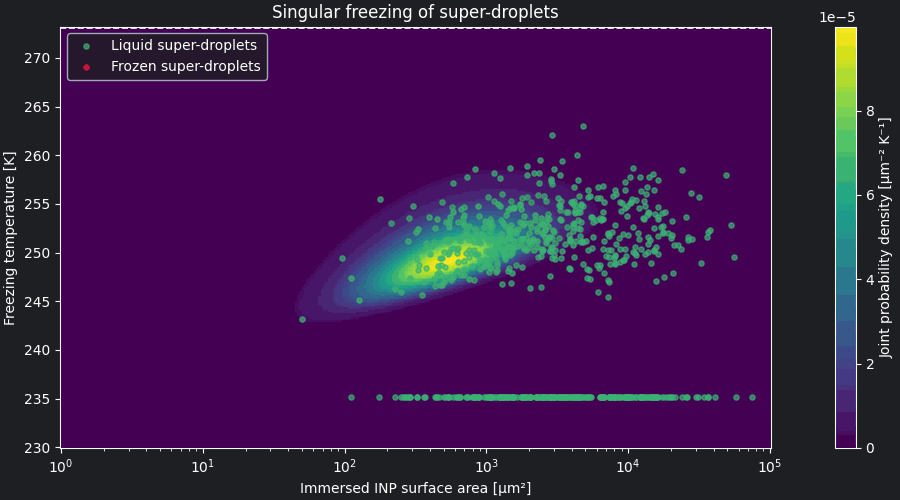

HTML(value="<a href='./tmphsm_jppw.gif' target='_blank'>./tmphsm_jppw.gif</a><br>")

In [4]:
from PySDM.dynamics.collisions.collision_kernels import Golovin
from PySDM.dynamics import Coalescence
from matplotlib import pyplot as plt


collision = Coalescence(collision_kernel=Golovin(b=10**5))
particulator = make_particulator_case(singular=True, seed=444, T0=T0,collision=collision)
r_before = particulator.attributes["radius"].to_ndarray().copy()
multi_before = particulator.attributes["multiplicity"].to_ndarray().copy()
#particulator.dynamics["Freezing"].enable =False
particulator.advance(100)

r_after = particulator.attributes["radius"].to_ndarray().copy()
multi_after = particulator.attributes["multiplicity"].to_ndarray().copy()

bins = np.geomspace(50,100,50) * si.um
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(
    r_before / si.um,
    bins=bins / si.um,
    weights=multi_before,
    density=True,
    histtype="step",
    linewidth=2,
    label="Before collisions",
)
ax.hist(
    r_after / si.um,
    bins=bins / si.um,
    weights=multi_after,
    density=True,
    histtype="step",
    linewidth=2,
    label="After 100 collision steps",
)

ax.set_xscale("log")
ax.set_xlabel(r"Wet radius [$\mu$m]")
ax.set_ylabel("Normalised droplet-number distribution")
ax.legend()
ax.grid(alpha=0.25)
plt.show()
particulator.dynamics["Collision"].enable=False
particulator.dynamics["Freezing"].enable=True

cooling_rate = 2.05 * si.K / si.min
T0 = 273.15 * si.K
T_end = 236 * si.K
dt = particulator.dt
plot_func = make_freezing_frame(
    particulator,
    area,
    temperature,
    joint_pdf,
    T0,
    cooling_rate,
    singular=True,
)
n_steps = int(np.ceil((T0 - T_end) / (cooling_rate*dt)))
n_frames = 100
frame_steps = np.unique(np.linspace(1, n_steps, n_frames, dtype=int))
show_anim(plot_func, frame_steps, duration=0.05, loop=0)



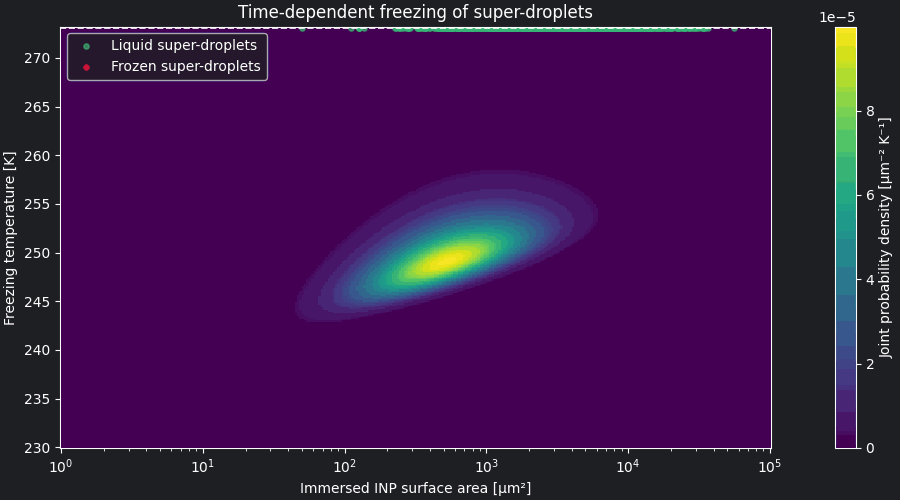

HTML(value="<a href='./tmpln8hwk_s.gif' target='_blank'>./tmpln8hwk_s.gif</a><br>")

In [5]:
collision = Coalescence(collision_kernel=Golovin(b=10**5))

particulator = make_particulator_case(singular=False, seed=444, T0=T0, collision=collision,)

particulator.advance(100)
particulator.dynamics["Collision"].enable = False

plot_func = make_freezing_frame(
    particulator,
    area,
    temperature,
    joint_pdf,
    T0,
    cooling_rate,
    singular=False,
)

n_steps = int(np.ceil(
    (T0 - T_end) / (cooling_rate * particulator.dt)
))

n_frames = 100
frame_steps = np.linspace(
    1,
    n_steps,
    n_frames,
).round().astype(int)

show_anim(
    plot_func,
    frame_steps,
    duration=0.05,
    loop=0,
)